# Performance on the test data set

Evaluate the kNN-score/XGBoost-cost TF-IDF policy selected in notebook 3, with frozen λ = 2.7142066911362983. Verify prediction agreement on validation before evaluating the 7,300 test prompts. This test split was inspected previously; these results are not a fresh untouched evaluation.

## 1. Configuration and source artifacts


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import joblib
from scipy.sparse import load_npz
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Fixed from notebook 3's validation comparison.
FROZEN_LAMBDA = 2.7142066911362983
LAMBDA_CONFIRMED = True
FROZEN_REFERENCE_LLM = "gpt-4-1106-preview"
REFERENCE_CONFIRMED = True

PROJECT_ROOT_OVERRIDE = None          # Optional absolute project root
FULL_RUN_DIR_OVERRIDE = None          # Optional absolute path to model outputs/full
SCORE_TYPE = "expected"
FEATURE = "tfidf"
SCORE_METHOD = "kNN"
COST_METHOD = "XGBoost"
METHOD = "kNN score + XGBoost cost"
RNG_SEED = 42
BOOTSTRAP_REPLICATES = 2000

cwd = Path.cwd().resolve()
project_candidates = [cwd, *cwd.parents]
if PROJECT_ROOT_OVERRIDE is not None:
    project_candidates = [Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()]
project_root = next((p for p in project_candidates if
    (p / "1_data_preparation/data/processed/char_tfidf_50k/preprocessing.joblib").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Cannot identify project root. Set PROJECT_ROOT_OVERRIDE.")
run_dir = (Path(FULL_RUN_DIR_OVERRIDE).expanduser().resolve() if FULL_RUN_DIR_OVERRIDE else
           project_root / "2_Router_Training/experiment_outputs/score_classification_5class/full")
required = ("experiment_manifest.json", "predictions_manifest.csv", "run_status.json", "xgb_models.joblib")
for f in required:
    if not (run_dir / f).is_file():
        raise FileNotFoundError(f"Missing modeling artifact: {run_dir / f}")
manifest = json.loads((run_dir / "experiment_manifest.json").read_text())
status = json.loads((run_dir / "run_status.json").read_text())
assert status.get("mode") == "full" and status.get("status") == "completed", status
assert manifest.get("mode") == "full" and manifest.get("test_used") is False
assert manifest.get("evaluation_split") == "calibration"
assert manifest.get("validation_role") == "downstream routing-policy development"
model_names = list(manifest["model_names"])
assert len(model_names) == 11 and "gpt-4-1106-preview" in model_names
selected_score_k = int(manifest["selected_knn_score_k"][FEATURE])
assert selected_score_k > 0
prediction_manifest = pd.read_csv(run_dir / "predictions_manifest.csv")

def validation_bundle(method):
    matching = prediction_manifest.loc[
        (prediction_manifest["method"] == method) &
        (prediction_manifest["embedding"] == FEATURE) &
        (prediction_manifest["split"] == "validation")
    ]
    assert len(matching) == 1, f"Expected one {method}/{FEATURE}/validation bundle"
    return matching.iloc[0]

score_bundle = validation_bundle(SCORE_METHOD)
cost_bundle = validation_bundle(COST_METHOD)
validation_score_prefix = str(score_bundle["prefix"])
validation_cost_prefix = str(cost_bundle["prefix"])
assert int(score_bundle["score_k"]) == selected_score_k
assert (run_dir / f"{validation_score_prefix}_expected_score.pkl").is_file()
assert (run_dir / f"{validation_cost_prefix}_dollar_cost.pkl").is_file()

print("Completed model run:", manifest["run_id"])
print("Validation score/cost bundles:", validation_score_prefix, validation_cost_prefix)
print("kNN score neighbors:", selected_score_k, "| Cost model:", COST_METHOD)
print("Candidates:", len(model_names), "(including GPT-4)")
if not (LAMBDA_CONFIRMED and REFERENCE_CONFIRMED and
        FROZEN_LAMBDA is not None and np.isfinite(FROZEN_LAMBDA) and FROZEN_LAMBDA >= 0 and
        FROZEN_REFERENCE_LLM in model_names):
    raise RuntimeError("Freeze λ and the validation-chosen reference before accessing test data. Set both confirmation flags True.")
print("Frozen λ:", FROZEN_LAMBDA)
print("Frozen reference:", FROZEN_REFERENCE_LLM)

Completed model run: 20261029T023425_449901Z
Validation score/cost bundles: pred_05_validation pred_09_validation
kNN score neighbors: 100 | Cost model: XGBoost
Candidates: 11 (including GPT-4)
Frozen λ: 2.7142066911362983
Frozen reference: gpt-4-1106-preview


**Results:** The policy uses 11 candidates, kNN scores with k = 100, XGBoost costs and TF-IDF features. λ = 2.7142066911362983 and GPT-4-1106-preview are fixed from validation. GPT-4 remains selectable.

## 2. Reconstruct predictions and check validation agreement

Rebuild cosine neighbors from training TF-IDF features and load the saved XGBoost cost regressors. Preserve training’s neighbor selection, cost scaling and positivity floor. Compare both predictions with their validation exports.

In [2]:
prep = project_root / "1_data_preparation" / "data" / "processed"
table_dir = prep / "char_tfidf_50k"
preprocessing = joblib.load(table_dir / "preprocessing.joblib")
assert list(preprocessing["model_names"]) == model_names
n_tfidf_features = len(preprocessing["tfidf_vectorizer"].vocabulary_)

def load_tfidf(split):
    # Match training: vocabulary columns only, float32 CSR.
    return load_npz(table_dir / f"X_{split}.npz")[:, :n_tfidf_features].astype(np.float32).tocsr()

support = np.asarray(manifest["score_support"], dtype=float)
assert support.shape == (5,)
train_questions = pd.read_pickle(table_dir / "train_questions.pkl")
train_scores = pd.read_pickle(table_dir / "train_scores.pkl")
train_costs = pd.read_pickle(table_dir / "train_costs.pkl")
validation_questions = pd.read_pickle(table_dir / "validation_questions.pkl")
for q, s, c in [(train_questions, train_scores, train_costs)]:
    assert q.index.is_unique and q.index.equals(s.index) and q.index.equals(c.index)
    assert s.columns.tolist() == c.columns.tolist() == model_names
X_train = load_tfidf("train")
X_validation = load_tfidf("validation")
assert X_train.shape[0] == len(train_questions)
assert X_validation.shape == (len(validation_questions), X_train.shape[1])
training_values = train_scores.to_numpy(dtype=float)
training_classes = np.abs(training_values[..., None] - support).argmin(axis=2)
assert selected_score_k <= len(train_questions)
cost_models = joblib.load(run_dir / "xgb_models.joblib")[FEATURE]["cost_regressor"]
cost_means = np.asarray(manifest["training_cost_means"], dtype=float)
assert len(cost_models) == len(cost_means) == len(model_names)
assert all(model.n_features_in_ == X_train.shape[1] for model in cost_models)

nn = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1).fit(X_train)
def predict(X, batch_size=128):
    """Reproduce kNN score probabilities and saved XGBoost dollar-cost predictions."""
    n = X.shape[0]
    p = np.empty((n, len(model_names), len(support)), dtype=float)
    # Preserve training-export neighbor selection and tie behavior.
    max_k = max(int(k) for k in manifest["k_values"])
    assert max_k >= selected_score_k
    for start in range(0, n, batch_size):
        stop = min(start + batch_size, n)
        neighbor_idx = nn.kneighbors(X[start:stop], n_neighbors=max_k, return_distance=False)
        z = training_classes[neighbor_idx[:, :selected_score_k]]
        p[start:stop] = (z[..., None] == np.arange(len(support))).mean(axis=1)
    # Match training's positivity floor and conversion back to dollars.
    c = np.column_stack([
        np.maximum(model.predict(X), 1e-6) * cost_means[j]
        for j, model in enumerate(cost_models)
    ])
    return p, c

p_validation, c_validation = predict(X_validation)
validation_pred_score = pd.DataFrame(p_validation @ support,
                                      index=validation_questions.index, columns=model_names)
validation_pred_cost = pd.DataFrame(c_validation,
                                     index=validation_questions.index, columns=model_names)
export_score = pd.read_pickle(run_dir / f"{validation_score_prefix}_expected_score.pkl")
export_cost = pd.read_pickle(run_dir / f"{validation_cost_prefix}_dollar_cost.pkl")
assert export_score.index.equals(validation_pred_score.index)
assert export_cost.index.equals(validation_pred_cost.index)
assert export_score.columns.tolist() == export_cost.columns.tolist() == model_names
score_diff = float(np.max(np.abs(export_score.to_numpy() - validation_pred_score.to_numpy())))
cost_diff = float(np.max(np.abs(export_cost.to_numpy() - validation_pred_cost.to_numpy())))
print("Max validation predicted-score discrepancy:", score_diff)
print("Max validation predicted-dollar-cost discrepancy:", cost_diff)
assert np.allclose(export_score.to_numpy(), validation_pred_score.to_numpy(), atol=1e-10, rtol=1e-8), "kNN score mismatch: stop before test"
assert np.allclose(export_cost.to_numpy(), validation_pred_cost.to_numpy(), atol=1e-10, rtol=1e-8), "XGBoost cost mismatch: stop before test"
print("Validation reproduction checks PASSED. Frozen configuration is ready for testing.")

Max validation predicted-score discrepancy: 0.0
Max validation predicted-dollar-cost discrepancy: 0.0
Validation reproduction checks PASSED. Frozen configuration is ready for testing.


**Results:** Maximum validation discrepancies are 0.0 for both expected scores and dollar costs. Both predictors reproduce the matching validation exports exactly.

## 3. Predict and route test prompts

Use kNN expected scores and XGBoost dollar costs. Select each model with `argmax(predicted_score - lambda * predicted_cost)` before loading test outcomes.

In [3]:
test_questions = pd.read_pickle(table_dir / "test_questions.pkl")
X_test = load_tfidf("test")
assert X_test.shape == (len(test_questions), X_train.shape[1])
p_test, c_test = predict(X_test)
predicted_scores = pd.DataFrame(p_test @ support, index=test_questions.index, columns=model_names)
predicted_costs = pd.DataFrame(c_test, index=test_questions.index, columns=model_names)
assert np.allclose(p_test.sum(axis=2), 1, atol=1e-10)
assert np.isfinite(predicted_scores.to_numpy()).all()
assert (predicted_costs.to_numpy() > 0).all()

objective = predicted_scores.to_numpy() - FROZEN_LAMBDA * predicted_costs.to_numpy()
choices = np.argmax(objective, axis=1)
selected_models = np.asarray(model_names)[choices]
print("Frozen policy selected (model counts):")
display(pd.Series(selected_models).value_counts().to_frame("test_questions"))

Frozen policy selected (model counts):


,test_questions
gpt-4-1106-preview,5073
claude-v2,898
claude-instant-v1,561
zero-one-ai/Yi-34B-Chat,550
gpt-3.5-turbo-1106,86
mistralai/mistral-7b-chat,42
mistralai/mixtral-8x7b-chat,32
meta/code-llama-instruct-34b-chat,29
claude-v1,25
WizardLM/WizardLM-13B-V1.2,3


**Results:** The policy assigns 5,073 of 7,300 prompts to GPT-4, 898 to Claude-v2 and 561 to Claude-instant-v1. All 11 candidates are selected at least once.

## 4. Calculate recorded score and cost

Load aligned test outcomes and compare routed responses with the fixed reference. Fractional grades are evaluated as mean recorded score, not binary accuracy.

In [4]:
true_scores = pd.read_pickle(table_dir / "test_scores.pkl")
true_costs = pd.read_pickle(table_dir / "test_costs.pkl")
assert test_questions.index.is_unique
assert test_questions.index.equals(true_scores.index) and test_questions.index.equals(true_costs.index)
assert true_scores.columns.tolist() == true_costs.columns.tolist() == model_names
S = true_scores.to_numpy(dtype=float)
C = true_costs.to_numpy(dtype=float)
assert np.all(np.isfinite(S)) and np.all((0 <= S) & (S <= 1))
assert np.all(np.isfinite(C)) and np.all(C > 0)
idx = np.arange(len(test_questions))
selected = pd.DataFrame({
    "selected_model": selected_models,
    "predicted_score": predicted_scores.to_numpy()[idx, choices],
    "actual_score": S[idx, choices],
    "predicted_cost_usd": predicted_costs.to_numpy()[idx, choices],
    "actual_cost_usd": C[idx, choices],
}, index=test_questions.index)
selected.index.name = "sample_id"
ref = FROZEN_REFERENCE_LLM
r_score = selected["actual_score"].to_numpy()
r_cost = selected["actual_cost_usd"].to_numpy()
b_score = true_scores[ref].to_numpy(dtype=float)
b_cost = true_costs[ref].to_numpy(dtype=float)
router_mean_score = float(r_score.mean())
ref_mean_score = float(b_score.mean())
router_mean_cost = float(r_cost.mean())
ref_mean_cost = float(b_cost.mean())
score_delta = router_mean_score - ref_mean_score
savings = 1 - router_mean_cost / ref_mean_cost
strict_binary = bool(np.all(np.isin(S, [0., 1.])))
print("Recorded test outcomes strictly binary?", strict_binary)
print(f"Routed mean recorded score: {router_mean_score:.6f}")
print(f"Reference mean recorded score: {ref_mean_score:.6f}")
print(f"Routed score difference: {score_delta:+.6f}")
print(f"Mean routed dollar cost: ${router_mean_cost:.8f}")
print(f"Mean reference dollar cost: ${ref_mean_cost:.8f}")
print(f"Relative cost savings: {savings:.2%}")
if not strict_binary:
    print("Binary accuracy, Brier and binary log loss are NOT reported from graded scores.")

Recorded test outcomes strictly binary? False
Routed mean recorded score: 0.780705
Reference mean recorded score: 0.779795
Routed score difference: +0.000911
Mean routed dollar cost: $0.00203463
Mean reference dollar cost: $0.00328008
Relative cost savings: 37.97%
Binary accuracy, Brier and binary log loss are NOT reported from graded scores.


**Results:** Mean score is 0.780705 versus 0.779795 for GPT-4 (difference +0.000911). Historical mean response cost is $0.00203463 versus $0.00328008, a 37.97% reduction.

## 5. Diagnostics and uncertainty

Calculate per-model/routed cost errors and 2,000 paired row-bootstrap intervals. Binary metrics require strictly binary labels. The cost Gamma loss uses `y/pred - log(y/pred) - 1`.

In [5]:
P = predicted_scores.to_numpy(dtype=float)
PC = predicted_costs.to_numpy(dtype=float)
EPS = 1e-12

def cost_metric_rows(y, pred, label):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert y.shape == pred.shape and np.all(y > 0) and np.all(pred > 0)
    gamma_deviance = y / pred - np.log(y / pred) - 1
    return {
        "group": label,
        "cost_mse_usd2": float(np.mean((pred - y)**2)),
        "cost_mae_usd": float(np.mean(np.abs(pred - y))),
        "cost_gamma_loss": float(np.mean(gamma_deviance)),
        "cost_wape": float(np.abs(pred - y).sum() / y.sum()),
    }

cost_diagnostics = pd.DataFrame([
    cost_metric_rows(C[:,j], PC[:,j], model_names[j]) for j in range(len(model_names))
] + [cost_metric_rows(r_cost, selected["predicted_cost_usd"], "ROUTED_SELECTION")])
# Equal-weight mean across models for each per-model diagnostic
mean_llm_diagnostics = cost_diagnostics.iloc[:len(model_names)].drop(columns="group").mean()
print("Cost prediction diagnostics by model, including the selected router:")
display(cost_diagnostics)
print("Equal-weight average across candidate LLMs:")
display(mean_llm_diagnostics.to_frame("mean_across_llms"))

rng = np.random.default_rng(RNG_SEED)
boot_delta, boot_savings = [], []
for _ in range(BOOTSTRAP_REPLICATES):
    ii = rng.integers(0, len(r_score), size=len(r_score))
    boot_delta.append(float((r_score[ii] - b_score[ii]).mean()))
    boot_savings.append(float(1 - r_cost[ii].mean() / b_cost[ii].mean()))
delta_ci = np.quantile(boot_delta, [.025, .975])
savings_ci = np.quantile(boot_savings, [.025, .975])

score_proxy_brier_per_llm = None
binary_log_loss_per_llm = None
if strict_binary:
    score_proxy_brier_per_llm = ((P - S) ** 2).mean(axis=0)
    clipped = np.clip(P, EPS, 1-EPS)
    binary_log_loss_per_llm = -(S*np.log(clipped) + (1-S)*np.log1p(-clipped)).mean(axis=0)
    print("Binary metrics computed using expected graded-score predictions as probability proxies;")
    print("these were NOT trained as binary probability estimators.")
else:
    print("Binary Brier and binary log loss unavailable (graded original scores).")

scorecard = pd.DataFrame([{
    "method": METHOD, "score_method": SCORE_METHOD, "cost_method": COST_METHOD,
    "embedding": FEATURE, "score_type": SCORE_TYPE,
    "frozen_lambda": float(FROZEN_LAMBDA), "reference_llm": ref,
    "test_questions": len(test_questions), "candidate_llms": len(model_names),
    "score_neighbor_k": selected_score_k, "cost_neighbor_k": None,
    "score_label_type": "strict_binary" if strict_binary else "graded_0_to_1",
    "routed_mean_recorded_score": router_mean_score,
    "reference_mean_recorded_score": ref_mean_score,
    "score_difference_vs_reference": score_delta,
    "score_difference_ci95_lower": float(delta_ci[0]),
    "score_difference_ci95_upper": float(delta_ci[1]),
    "routed_mean_cost_usd": router_mean_cost,
    "reference_mean_cost_usd": ref_mean_cost,
    "relative_cost_savings": savings,
    "savings_ci95_lower": float(savings_ci[0]),
    "savings_ci95_upper": float(savings_ci[1]),
    "routed_accuracy_binary": router_mean_score if strict_binary else np.nan,
    "accuracy_change_binary": score_delta if strict_binary else np.nan,
    "candidate_binary_brier_mean_proxy": float(np.mean(score_proxy_brier_per_llm)) if strict_binary else np.nan,
    "candidate_binary_logloss_mean_proxy": float(np.mean(binary_log_loss_per_llm)) if strict_binary else np.nan,
    "candidate_cost_mse_mean_usd2": mean_llm_diagnostics["cost_mse_usd2"],
    "candidate_cost_mae_mean_usd": mean_llm_diagnostics["cost_mae_usd"],
    "candidate_cost_gamma_loss_mean": mean_llm_diagnostics["cost_gamma_loss"],
    "routed_cost_mse_usd2": cost_diagnostics.iloc[-1]["cost_mse_usd2"],
    "routed_cost_mae_usd": cost_diagnostics.iloc[-1]["cost_mae_usd"],
    "routed_cost_gamma_loss": cost_diagnostics.iloc[-1]["cost_gamma_loss"],
    "precision_recall": "undefined_without_threshold_or_positive_class",
    "end_to_end_latency": "unavailable_no_latency_records",
    "gpt4_selection_fraction": float((selected_models == "gpt-4-1106-preview").mean()),
}])
display(scorecard.T.rename(columns={0:"Test-split result"}))

if strict_binary:
    binary_diagnostics = pd.DataFrame({
        "llm": model_names,
        "brier_expected_score_proxy": score_proxy_brier_per_llm,
        "binary_logloss_expected_score_proxy": binary_log_loss_per_llm
    })
    display(binary_diagnostics)
else:
    binary_diagnostics = pd.DataFrame(columns=["llm", "brier_expected_score_proxy", "binary_logloss_expected_score_proxy"])

Cost prediction diagnostics by model, including the selected router:


,group,cost_mse_usd2,cost_mae_usd,cost_gamma_loss,cost_wape
0,WizardLM/WizardLM-13B-V1.2,2.383939e-10,0.000008,0.011449,0.104065
1,claude-instant-v1,4.552694e-09,0.000031,0.015810,0.132020
2,claude-v1,5.308369e-07,0.000286,0.016835,0.133076
3,claude-v2,3.612629e-07,0.000291,0.013248,0.120344
4,gpt-3.5-turbo-1106,3.795293e-09,0.000030,0.013329,0.122785
5,gpt-4-1106-preview,1.667159e-06,0.000557,0.023897,0.169732
6,meta/code-llama-instruct-34b-chat,1.118221e-09,0.000017,0.010419,0.099130
7,meta/llama-2-70b-chat,2.777540e-09,0.000020,0.010957,0.099900
8,mistralai/mistral-7b-chat,7.837331e-10,0.000007,0.029828,0.153767
9,mistralai/mixtral-8x7b-chat,6.986579e-10,0.000014,0.009947,0.101233


Equal-weight average across candidate LLMs:


,mean_across_llms
cost_mse_usd2,2.341222e-07
cost_mae_usd,1.165786e-04
cost_gamma_loss,1.545156e-02
cost_wape,1.236637e-01


Binary Brier and binary log loss unavailable (graded original scores).


,Test-split result
method,kNN score + XGBoost cost
score_method,kNN
cost_method,XGBoost
embedding,tfidf
score_type,expected
frozen_lambda,2.714207
reference_llm,gpt-4-1106-preview
test_questions,7300
candidate_llms,11
score_neighbor_k,100


**Results:** The 95% score-difference interval is [-0.002809, +0.004651]; the savings interval is [36.67%, 39.25%]. These intervals do not establish superior or equivalent quality. Row resampling does not account for duplicate/task dependence or earlier test inspection. Binary metrics and latency are unavailable.

## 6. Compare the router with fixed candidates

Plot mean recorded score against historical response cost for every fixed candidate and the frozen router. Label the reference separately while retaining it in the candidate pool.

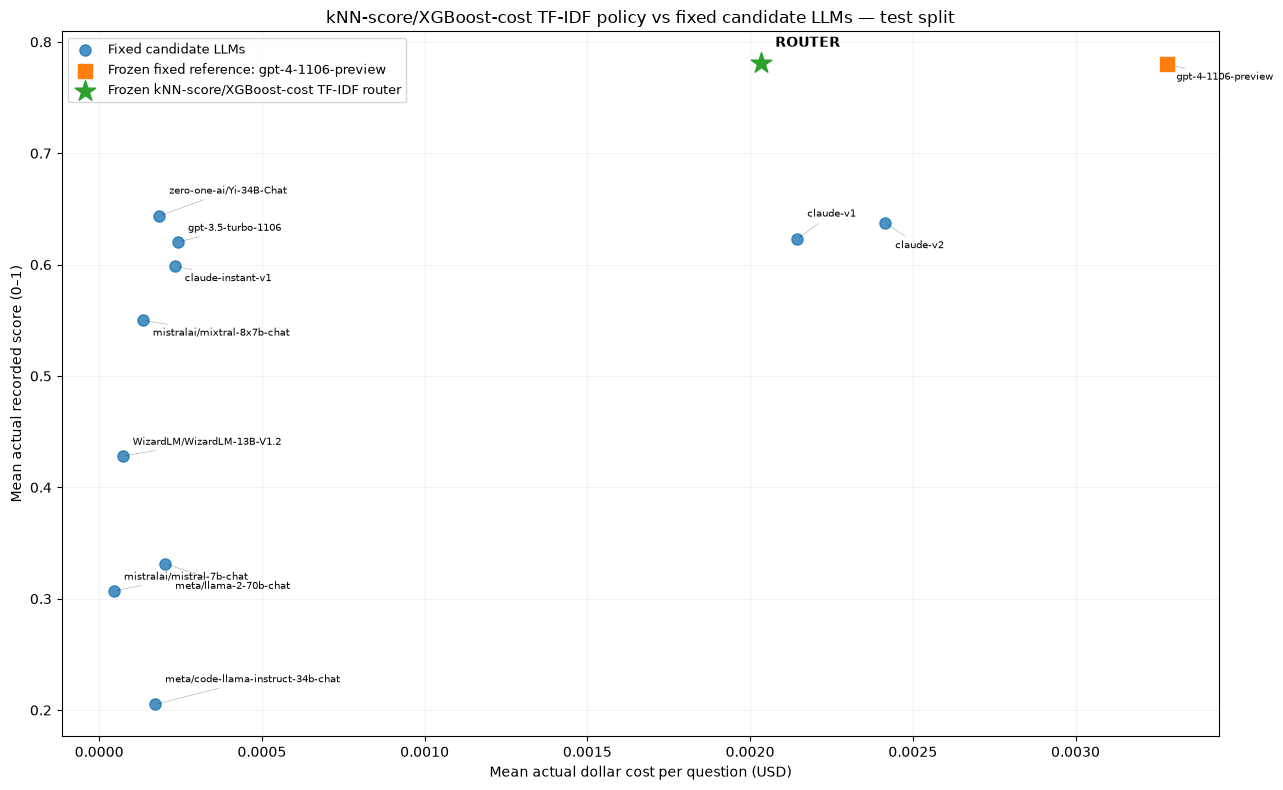

,llm,mean_recorded_score,mean_cost_usd,strategy
8,mistralai/mistral-7b-chat,0.307096,0.000046,Fixed LLM
0,WizardLM/WizardLM-13B-V1.2,0.428226,0.000073,Fixed LLM
9,mistralai/mixtral-8x7b-chat,0.549938,0.000135,Fixed LLM
6,meta/code-llama-instruct-34b-chat,0.205068,0.000173,Fixed LLM
10,zero-one-ai/Yi-34B-Chat,0.643822,0.000185,Fixed LLM
7,meta/llama-2-70b-chat,0.331281,0.000203,Fixed LLM
1,claude-instant-v1,0.598945,0.000233,Fixed LLM
4,gpt-3.5-turbo-1106,0.620404,0.000243,Fixed LLM
11,ROUTER,0.780705,0.002035,Frozen router
2,claude-v1,0.623164,0.002146,Fixed LLM


GPT-4 selected in 5073 of 7300 test questions.


In [6]:
fixed = pd.DataFrame({
    "mean_recorded_score": true_scores.mean(axis=0),
    "mean_cost_usd": true_costs.mean(axis=0),
})
fixed.index.name = "llm"
assert fixed.index.tolist() == model_names

fig, ax = plt.subplots(figsize=(13, 8))
other = fixed.drop(index=ref)
ax.scatter(other["mean_cost_usd"], other["mean_recorded_score"],
           marker="o", s=65, alpha=.8, label="Fixed candidate LLMs")
ax.scatter([ref_mean_cost], [ref_mean_score], marker="s", s=115,
           label=f"Frozen fixed reference: {ref}", zorder=4)
ax.scatter([router_mean_cost], [router_mean_score], marker="*", s=240,
           label="Frozen kNN-score/XGBoost-cost TF-IDF router", zorder=5)

# Cycle label offsets to limit overlaps.
for j, (name, r) in enumerate(fixed.iterrows()):
    dy = (8, -11, 16, -18)[j % 4]
    ax.annotate(name, (r["mean_cost_usd"], r["mean_recorded_score"]),
                xytext=(7, dy), textcoords="offset points", fontsize=7.5,
                arrowprops={"arrowstyle":"-", "lw":0.35, "alpha":0.4})
ax.annotate("ROUTER", (router_mean_cost, router_mean_score),
            xytext=(10, 12), textcoords="offset points", fontsize=10, weight="bold")
ax.set_xlabel("Mean actual dollar cost per question (USD)")
ax.set_ylabel("Mean actual recorded score (0–1)")
ax.set_title("kNN-score/XGBoost-cost TF-IDF policy vs fixed candidate LLMs — test split")
ax.grid(alpha=.15)
ax.legend(loc="best", fontsize=9)
fig.tight_layout()
plt.show()

fixed_comparison = pd.concat([fixed.reset_index().assign(strategy="Fixed LLM"),
    pd.DataFrame([{"llm":"ROUTER", "mean_recorded_score":router_mean_score,
                   "mean_cost_usd":router_mean_cost,"strategy":"Frozen router"}])],ignore_index=True)
display(fixed_comparison.sort_values("mean_cost_usd"))
print(f"GPT-4 selected in {(selected_models == 'gpt-4-1106-preview').sum()} of {len(selected_models)} test questions.")

**Results:** The router costs less than GPT-4 and has a slightly higher observed mean grade. GPT-4 supplies 69.49% of routed responses. Costs exclude router overhead; no end-to-end latency was measured.

## 7. Export the evaluation bundle

Write the scorecard, cost diagnostics, selected models, predictions, comparison plot and frozen configuration to a timestamped directory under `4_Final_Test/experiment_outputs/`.

In [ ]:
out_base = project_root / "4_Final_Test" / "experiment_outputs"
out_dir = out_base / datetime.now(timezone.utc).strftime("knn_xgb_tfidf_test_%Y%m%dT%H%M%S_%fZ")
out_dir.mkdir(parents=True, exist_ok=False)
scorecard.to_csv(out_dir / "test_kpi_scorecard.csv", index=False)
cost_diagnostics.to_csv(out_dir / "test_cost_diagnostics_per_llm.csv", index=False)
binary_diagnostics.to_csv(out_dir / "test_binary_diagnostics_if_available.csv", index=False)
selected.to_csv(out_dir / "selected_models_test.csv")
fixed_comparison.to_csv(out_dir / "fixed_llm_comparison.csv", index=False)
predicted_scores.to_pickle(out_dir / "test_predicted_expected_scores.pkl")
predicted_costs.to_pickle(out_dir / "test_predicted_costs.pkl")
fig.savefig(out_dir / "test_score_cost_labeled.png", dpi=180, bbox_inches="tight")
config = {
    "method":METHOD, "score_method":SCORE_METHOD, "cost_method":COST_METHOD,
    "feature":FEATURE, "score_type":SCORE_TYPE,
    "lambda":float(FROZEN_LAMBDA), "reference_llm":ref,
    "reference_selection_provenance":"frozen_policy_validation",
    "lambda_confirmed_before_test": LAMBDA_CONFIRMED,
    "reference_confirmed_before_test": REFERENCE_CONFIRMED,
    "model_run":str(run_dir), "model_run_created_utc":manifest.get("created_utc"),
    "validation_score_prefix":validation_score_prefix,
    "validation_cost_prefix":validation_cost_prefix,
    "max_validation_score_difference":score_diff,
    "max_validation_cost_difference":cost_diff,
    "k_score":selected_score_k, "k_cost":None,
    "model_names":model_names,
    "binary_metrics_available":strict_binary,
    "policy_rule":"argmax(expected_5class_score - lambda * predicted_dollar_cost)",
    "test_previously_inspected":True,
    "note":"Configuration selected on validation; the test split was previously inspected with other policies, so this is not a fresh untouched evaluation.",
}
(out_dir / "frozen_configuration.json").write_text(json.dumps(config, indent=2))
print("Saved final test outputs to:", out_dir)

**Results:** Evaluation outputs are saved in `experiment_outputs/knn_xgb_tfidf_test_20261029T150655_167494Z/`, including the scorecard, diagnostics, predictions, selected models, comparison plot and frozen configuration.